# Шаг 2. Свёртка своими руками

Главная операция свёрточной сети — **свёртка** (convolution). Мы уже встречали её в сессии 2 (`cv2.filter2D`):
маленькая матрица весов — **ядро** или **фильтр**, обычно 3 × 3, — скользит по картинке. В каждой позиции
9 весов умножаются на 9 пикселей под ними, произведения складываются — получается **один пиксель результата**.

Результат свёртки называют **картой признаков** (feature map): она светлая там, где на картинке есть узор,
похожий на ядро, и тёмная там, где его нет.

Главное отличие от сессии 2: там ядра мы **придумывали сами**, а в свёрточной сети их веса **подбирает обучение**.

**Структура примера (алгоритм):**
1. Берём фото кошки и переводим в серый.
2. Задаём четыре ручных ядра: вертикальные границы, горизонтальные границы, размытие, резкость.
3. Считаем один пиксель свёртки вручную и сверяем с `F.conv2d`.
4. Применяем все ядра к картинке, затем **ReLU** и **пулинг** — три кирпичика свёрточной сети.
5. Создаём настоящий слой `nn.Conv2d` и считаем его веса — сравниваем с полносвязным слоем.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Берём кошку и делаем её серой

`torch.nn.functional` (`F`) — функции нейросетей без собственных весов: `conv2d`, `relu`, `max_pool2d`.

Ищем в проверочном наборе первую кошку (`labels == 0`). Для ручных ядер проще работать с одним каналом,
поэтому усредняем три канала: `image.mean(0, keepdim=True)` даёт форму `(1, 32, 32)`.

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

from common import CatsDogs, show

test = CatsDogs(train=False)
cat_index = (test.labels == 0).nonzero()[0].item()  # первая кошка в проверочном наборе
image, _ = test[cat_index]
gray = image.mean(0, keepdim=True)  # (3, 32, 32) → (1, 32, 32): среднее трёх каналов
print("Серая картинка:", tuple(gray.shape))

Серая картинка: (1, 32, 32)


## 2. Четыре ручных ядра

| Ядро | Что ищет | Как устроено |
|------|----------|--------------|
| **Собель по x** | вертикальные границы | слева веса −1, −2, −1, справа +1, +2, +1: реагирует, когда справа ярче, чем слева |
| **Собель по y** | горизонтальные границы | то же самое, повёрнутое: сверху минус, снизу плюс (`.T` — транспонирование) |
| **Размытие** | ничего не ищет, усредняет | все веса `1/9` — среднее 3 × 3 (как `cv2.blur`) |
| **Резкость** | подчёркивает детали | центр `5`, соседи `−1`: пиксель минус его соседи, усиленный |

In [2]:
sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])
KERNELS = {
    "vertical edges": sobel_x,
    "horizontal edges": sobel_x.T,
    "blur": torch.ones(3, 3) / 9,
    "sharpen": torch.tensor([[0., -1., 0.],
                             [-1., 5., -1.],
                             [0., -1., 0.]]),
}

## 3. Один пиксель свёртки вручную

Возьмём точку `(x=16, y=16)` в центре картинки:
1. вырезаем окно 3 × 3 вокруг неё: строки `y−1…y+1`, столбцы `x−1…x+1`;
2. перемножаем окно с ядром **поэлементно** (`*`) и складываем все 9 произведений (`.sum()`).

Затем то же самое делает `F.conv2d` сразу для всех позиций. Ей нужны 4-мерные тензоры:
- картинки — `(пачка, каналы, высота, ширина)`: добавляем ось пачки `gray[None]` → `(1, 1, 32, 32)`;
- ядра — `(выходные каналы, входные каналы, 3, 3)`: `kernel[None, None]` → `(1, 1, 3, 3)`.

`padding=1` дописывает рамку из нулей шириной 1 пиксель, чтобы окно 3 × 3 помещалось и у краёв —
тогда результат остаётся размером 32 × 32. Числа должны совпасть.

> Строго говоря, `F.conv2d` вычисляет **взаимную корреляцию** (ядро не переворачивается), но в нейросетях её по традиции называют свёрткой.

In [3]:
y, x = 16, 16
patch = gray[0, y - 1:y + 2, x - 1:x + 2]           # окно 3×3 вокруг точки
by_hand = (patch * sobel_x).sum().item()            # 9 умножений и сумма
result = F.conv2d(gray[None], sobel_x[None, None], padding=1)
print("Окно 3×3:\n", patch.numpy().round(2))
print(f"Вручную: {by_hand:.4f}   F.conv2d: {result[0, 0, y, x].item():.4f}")
print("Размер результата:", tuple(result.shape))

Окно 3×3:
 [[0.48 0.44 0.4 ]
 [0.4  0.38 0.38]
 [0.42 0.35 0.39]]
Вручную: -0.1477   F.conv2d: -0.1477
Размер результата: (1, 1, 32, 32)


## 4. Свёртка → ReLU → пулинг

Применяем все четыре ядра. А затем к карте вертикальных границ — ещё две операции, из которых состоит каждый блок свёрточной сети:

- **ReLU** (`max(0, v)`) обнуляет отрицательные значения. После Собеля «плюс» — переход от тёмного к светлому слева направо,
  «минус» — наоборот. ReLU оставляет только один вид переходов: так нейрон говорит «узор есть» или «узора нет».
- **Max-пулинг 2 × 2** (`F.max_pool2d(..., 2)`) делит карту на квадратики 2 × 2 и из каждого берёт **максимум**.
  Размер уменьшается вдвое: 32 × 32 → 16 × 16. Смысл: «узор был где-то в этом квадратике» — точное положение
  становится неважным, а следующий слой видит **вдвое большую** область исходной картинки.

Для показа карт с отрицательными числами используем палитру `bwr`: красное — положительное, синее — отрицательное.

> Обратите внимание на яркую рамку по краям карт границ: это след `padding=1`. За краем картинки ядро «видит» нули (чёрное),
> и переход от фото к чёрной рамке выглядит для него как сильная граница.

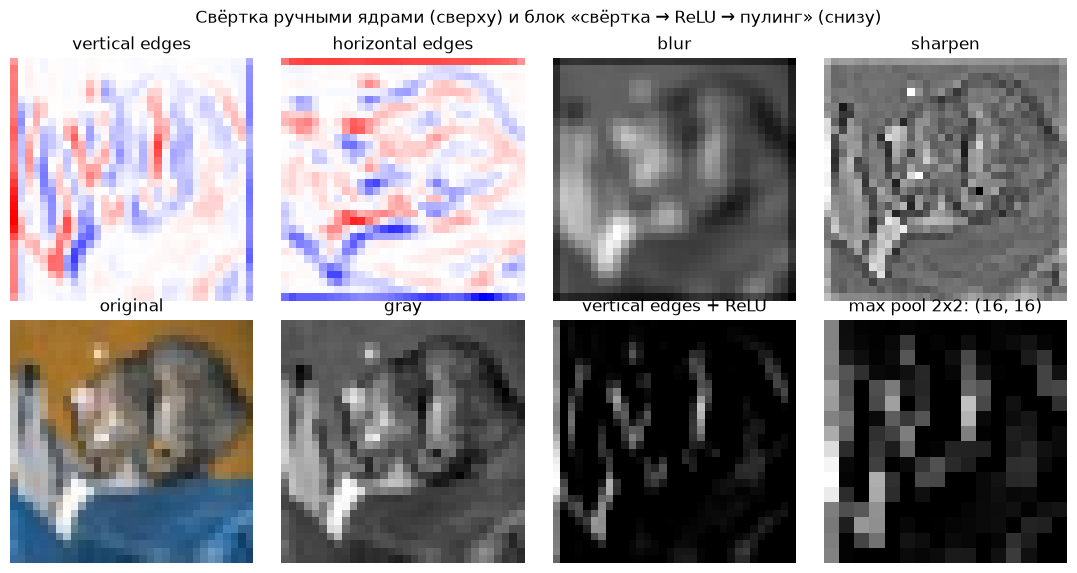

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.8))
for ax, (name, kernel) in zip(axes[0], KERNELS.items()):
    out = F.conv2d(gray[None], kernel[None, None], padding=1)[0, 0]
    limit = out.abs().max()
    ax.imshow(out, cmap="gray" if name in ("blur", "sharpen") else "bwr",
              vmin=None if name in ("blur", "sharpen") else -limit,
              vmax=None if name in ("blur", "sharpen") else limit)
    ax.set_title(name)

edges = F.conv2d(gray[None], sobel_x[None, None], padding=1)  # (1, 1, 32, 32)
relu = F.relu(edges)                                          # отрицательное → 0
pooled = F.max_pool2d(relu, 2)                                # 32×32 → 16×16
for ax, picture, title in zip(axes[1],
                              [image.permute(1, 2, 0), gray[0], relu[0, 0], pooled[0, 0]],
                              ["original", "gray", "vertical edges + ReLU", f"max pool 2x2: {tuple(pooled.shape[2:])}"]):
    ax.imshow(picture, cmap="gray", interpolation="nearest")
    ax.set_title(title)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Свёртка ручными ядрами (сверху) и блок «свёртка → ReLU → пулинг» (снизу)")
plt.tight_layout()
plt.savefig("conv_by_hand.png", dpi=100)
show()

## 5. Настоящий свёрточный слой `nn.Conv2d`

`nn.Conv2d(3, 16, kernel_size=3, padding=1)` — это **16 ядер** размером `3 × 3 × 3` (по кусочку 3 × 3 на каждый из 3 цветовых каналов)
плюс 16 смещений. Сначала веса случайные; обучение подберёт их так, чтобы ядра находили полезные для задачи узоры.

Слой превращает картинку `(1, 3, 32, 32)` в 16 карт признаков `(1, 16, 32, 32)`.

**Сколько весов?** `16 · 3 · 3 · 3 + 16 = 448`. Полносвязному слою, который из 3072 входов делает
такие же 16 · 32 · 32 = 16 384 выхода, понадобилось бы `3072 · 16 384 ≈ 50` миллионов весов!

Свёртка экономна благодаря двум идеям:
1. **локальность** — каждый выход смотрит только на маленькое окно 3 × 3, а не на всю картинку;
2. **общие веса** — одно и то же ядро применяется во всех позициях. Поэтому ухо найдётся и в левом углу, и в правом.

In [5]:
conv = nn.Conv2d(3, 16, kernel_size=3, padding=1)
print("Форма весов:", tuple(conv.weight.shape), "— 16 ядер по 3×3×3")
out = conv(image[None])
print("Вход:", tuple(image[None].shape), "→ выход:", tuple(out.shape))

conv_params = sum(p.numel() for p in conv.parameters())
dense_params = image.numel() * out.numel()
print(f"Весов у свёртки:             {conv_params}")
print(f"Весов у полносвязного слоя:  {dense_params:,}".replace(",", " "))

Форма весов: (16, 3, 3, 3) — 16 ядер по 3×3×3
Вход: (1, 3, 32, 32) → выход: (1, 16, 32, 32)
Весов у свёртки:             448
Весов у полносвязного слоя:  50 331 648


## Попробуйте сами

1. Придумайте ядро, которое ищет **диагональные** границы, и добавьте его в `KERNELS`.
2. Уберите `padding=1`. Какого размера стал результат свёртки? Почему?
3. Замените `F.max_pool2d` на `F.avg_pool2d` (среднее вместо максимума). Чем отличается результат?
4. Примените к картинке пулинг три раза подряд. Что остаётся от кошки на 4 × 4?